# Sharma & Oberoi 2020, Figure 4

Quiet Sun, 3 December 2015, 03:39–03:44 UT. Four minutes, one picture per frequency.

The paper’s picture is the **mean of ~570 half-second maps**, then converted to million K. A single frame is not Figure 4.

| | 108 MHz | 162 MHz | 217 MHz |
|---|---|---|---|
| Caption | 0.92 million K | 1.20 | 1.50 |
| His maps, paper flux | **0.89** | 1.00 | 1.06 |

Kernel: `solar-burst-multiview`. Run from the top.


## 1. Setup


In [1]:
from pathlib import Path
import json, sys, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.wcs import FITSFixedWarning
from IPython.display import Image, display
from matplotlib.patches import Circle, Ellipse

warnings.filterwarnings("ignore", category=FITSFixedWarning)
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

here = Path.cwd()
ROOT = here if (here / "src" / "solarburst").exists() else here.parent
sys.path.insert(0, str(ROOT / "src"))

from solarburst.maps import crop_around_sun, frequency_hz, header_cell_arcsec, hpc_extent, jybeam_to_tb, load_casa_2d
from solarburst.sharma2020 import last_clean_from_history, list_fits, CLEAN

print(ROOT)


/Users/csillag/Projects/solar-burst-multiview


## 2. Files


In [2]:
PATHS = {
    "his 4-min figure": ROOT / "figures" / "sharma2020" / "fig4_paper.png",
    "his kelvin cube": ROOT / "data" / "quiet2015" / "fig4_tb_perframe.npz",
    "his CASA frames": ROOT / "data" / "sharma2022" / "20151203_MWA" / "new_ms" / "fits",
    "flux": ROOT / "data" / "quiet2015" / "paper_flux",
    "our frames": ROOT / "data" / "quiet2015" / "paper_casa_su",
}
BANDS = ("108", "162", "217", "240")
CHAN = {"108": "084-085", "162": "125-126", "217": "169-170", "240": "187-188"}
CAPTION = {"108": 0.92, "162": 1.20, "217": 1.50, "240": None}
RSUN, FOV = 958.0, 2500.0

for k, p in PATHS.items():
    n = f"  ({len(list(p.glob('*')))} files)" if p.is_dir() and p.exists() else ""
    print(("ok " if p.exists() else "MISSING"), k, n)


ok  his 4-min figure 
ok  his kelvin cube 
ok  his CASA frames   (35948 files)
ok  flux   (17 files)
ok  our frames   (8 files)


## 3. His Figure 4 (mean of 570 frames, paper kelvin)

This is the map the caption quotes. Western patch, larger radio Sun at 108 MHz. Colour 0–1.7 million K.


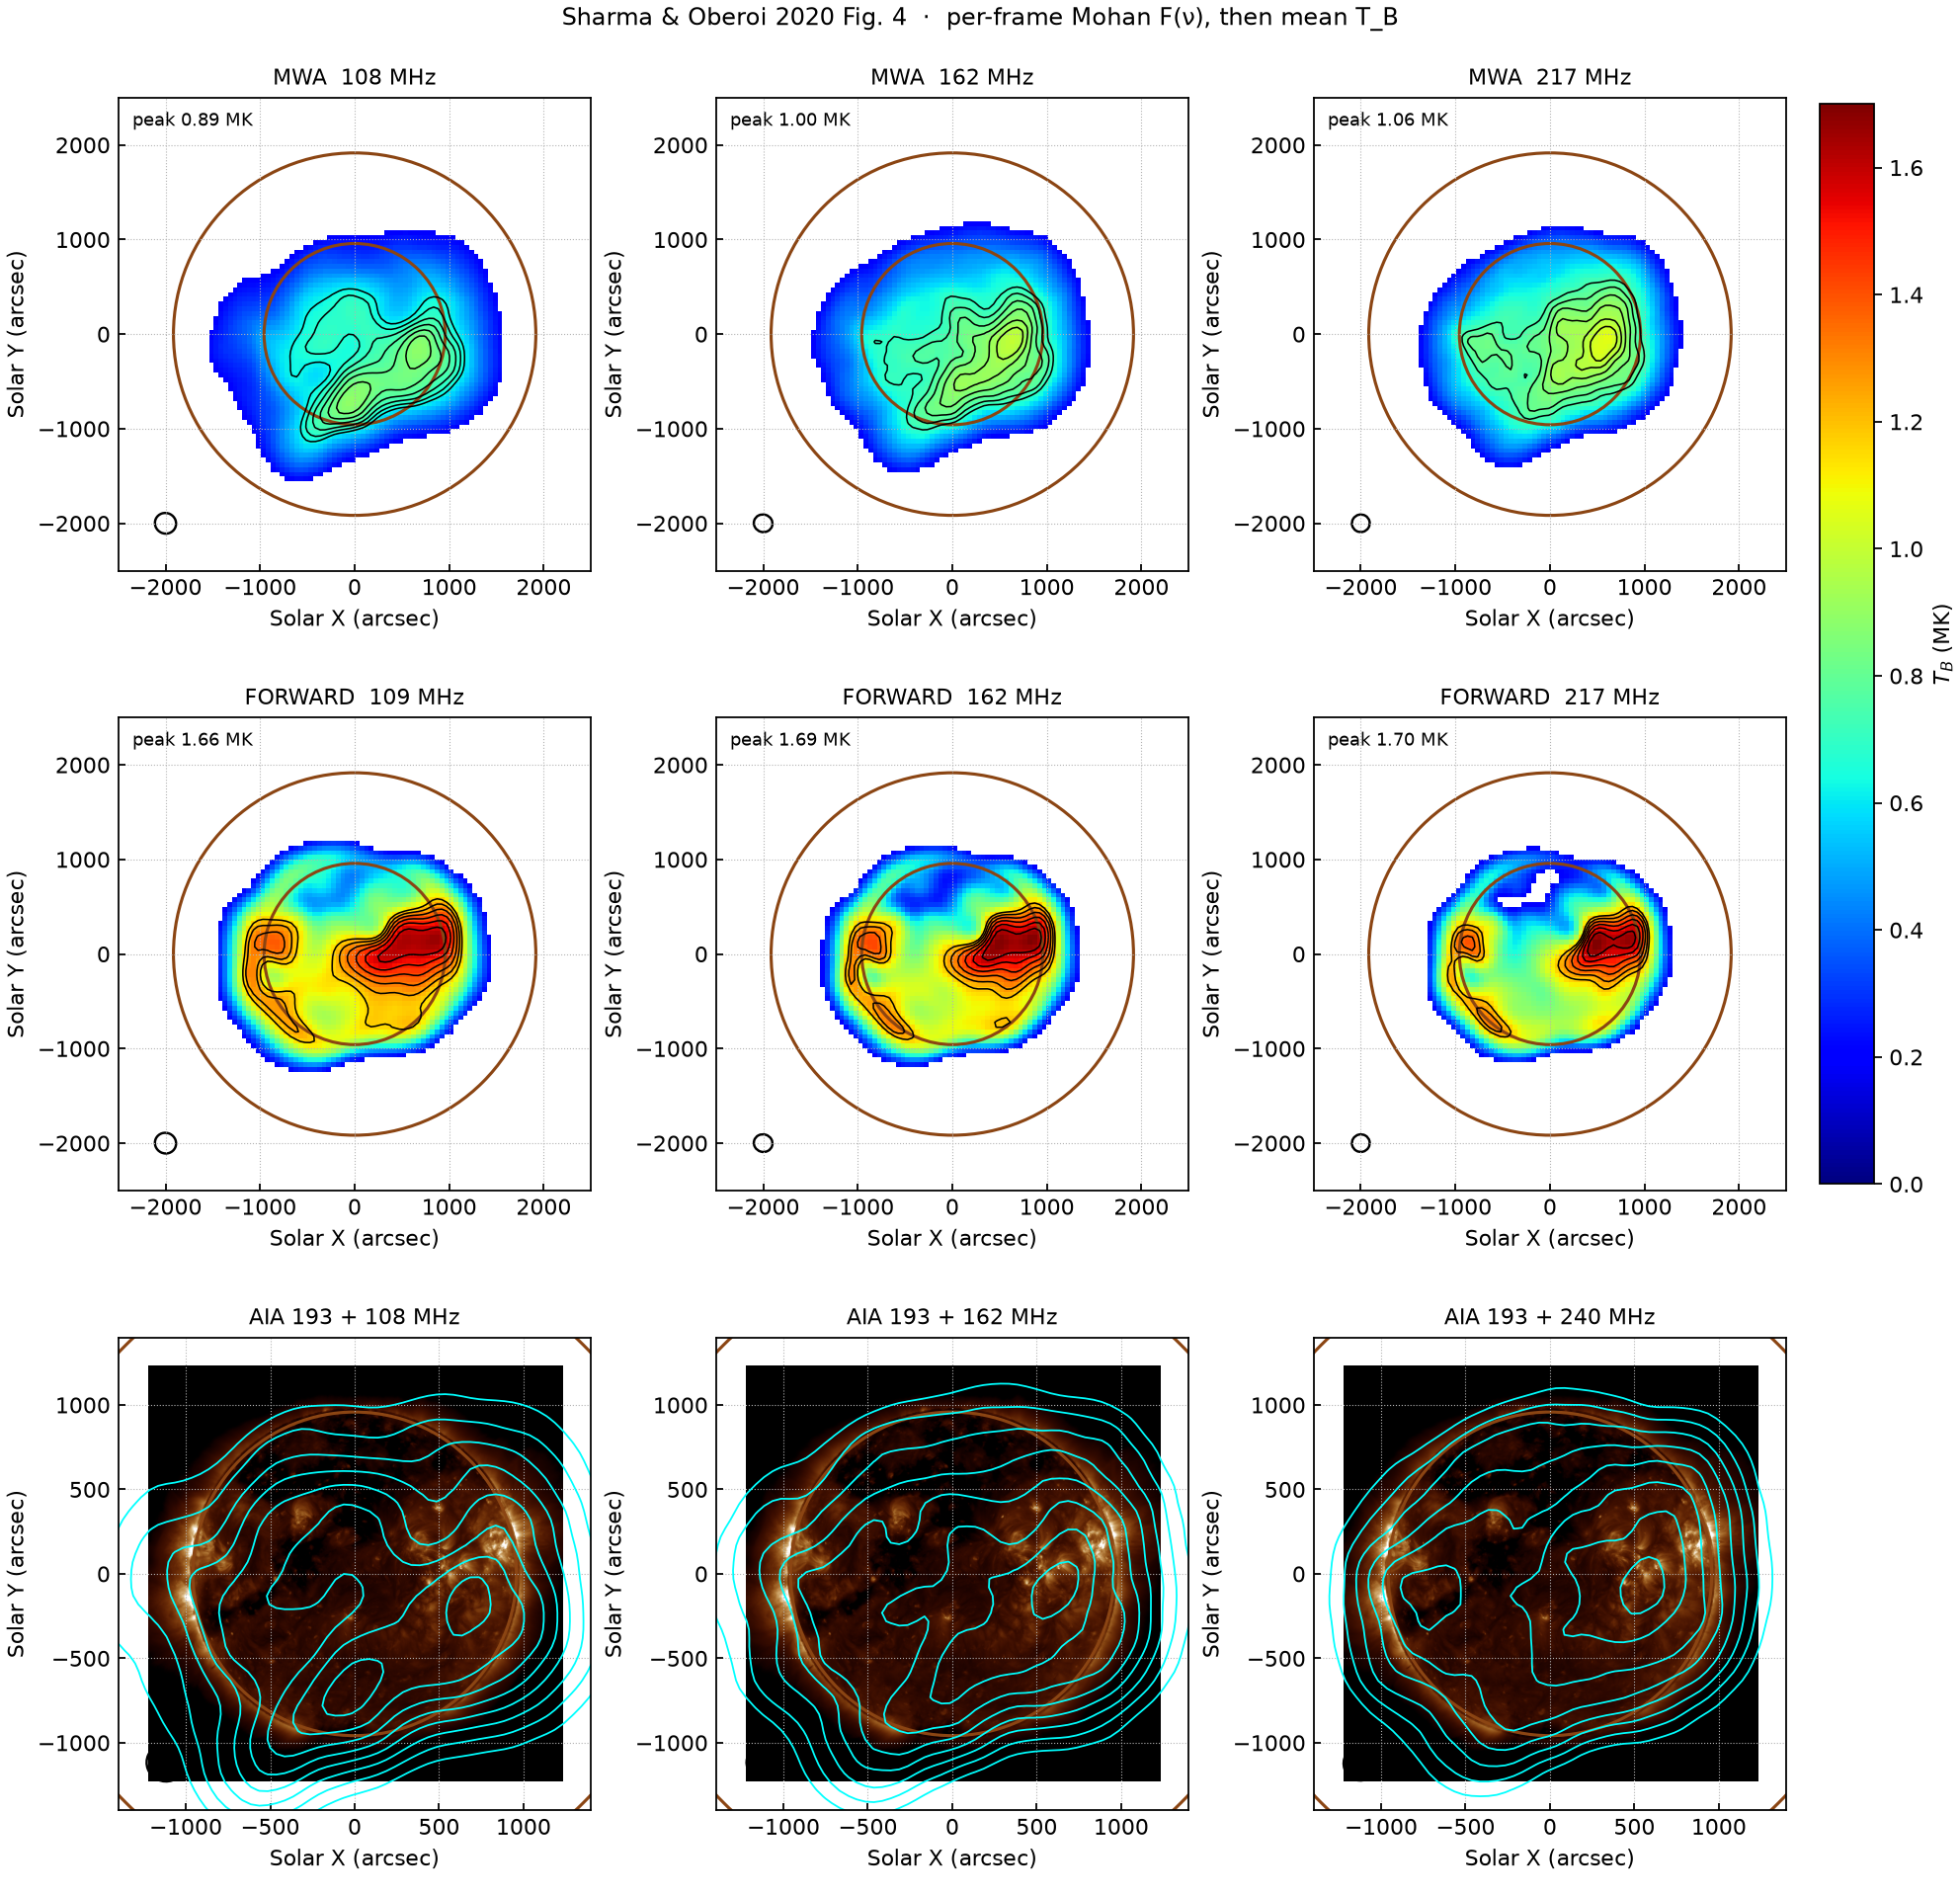

In [3]:
display(Image(filename=str(PATHS["his 4-min figure"]), width=880))


## 4. Numbers from that mean


In [4]:
z = np.load(PATHS["his kelvin cube"])
print(f"{'MHz':>5s}  {'frames':>6s}  {'peak MK':>8s}  {'caption':>8s}")
for lab in BANDS:
    cap = CAPTION[lab]
    cap_s = f"{cap:8.2f}" if cap else "       —"
    print(f"{lab:>5s}  {int(z[f'{lab}_n']):6d}  {z[f'{lab}_tb'].max()/1e6:8.3f}  {cap_s}")


  MHz  frames   peak MK   caption
  108     570     0.892      0.92
  162     570     0.996      1.20
  217     570     1.064      1.50
  240     570     0.621         —


## 5. How those 570 pictures were made

Read from his FITS, not guessed. CASA 5.3, SuperUniform mix of antenna pairings, 8000 cleaning steps. SuperUniform = count short and long pairings more evenly (tighter blob). Figure 4 is the **average** of the 570, not one of them.


In [5]:
fitsdir = PATHS["his CASA frames"]
for lab in BANDS:
    files = list_fits(fitsdir, CHAN[lab])
    rec = last_clean_from_history(files[0])
    print(f"{lab} MHz   {len(files)} frames   beam {rec['bmaj_arcsec']}″ × {rec['bmin_arcsec']}″")
    print(f"         {rec['origin']}   {rec.get('niter','')}   {rec.get('weighting','')[:40]}")
print("remake settings:", CLEAN["weighting"], "niter", CLEAN["niter"])


108 MHz   570 frames   beam 225.4″ × 217.7″
         CASA 5.3.0-143   Clean gain = 0.1, Niter = 8000, Threshold = 0 mJy   SuperUniform weighting over a square cel


162 MHz   570 frames   beam 198.3″ × 185.6″
         CASA 5.3.0-143   Clean gain = 0.1, Niter = 8000, Threshold = 0 mJy   SuperUniform weighting over a square cel
217 MHz   570 frames   beam 188.1″ × 185.7″
         CASA 5.3.0-143   Clean gain = 0.1, Niter = 8000, Threshold = 0 mJy   SuperUniform weighting over a square cel


240 MHz   570 frames   beam 209.0″ × 202.3″
         CASA 5.3.0-143   Clean gain = 0.1, Niter = 8000, Threshold = 0 mJy   SuperUniform weighting over a square cel
remake settings: superuniform niter 8000


## 6. Whole-Sun brightness (no picture)

CASA Jy/beam is on an arbitrary scale. Kelvin needs the true brightness of the whole Sun, measured from the short antenna pairings (Oberoi 2017) with the Galaxy *behind this Sun* (Haslam 1982). Then each frame is stretched so its disk equals that number, converted to kelvin, and the 570 are averaged.


In [6]:
print(f"{'MHz':>5s}  {'S_⊙ SFU':>10s}  {'stretch F(ν)':>12s}")
z = np.load(PATHS["his kelvin cube"])
for lab in BANDS:
    rec = json.loads((PATHS["flux"] / f"{lab}MHz_full.json").read_text())
    print(f"{lab:>5s}  {rec['s_odot_sfu']:10.3f}  {float(z[f'{lab}_f_nu_mean']):12.2f}")


  MHz     S_⊙ SFU  stretch F(ν)
  108       2.868         10.73
  162       6.500         12.26
  217      11.719         13.19
  240       8.166         13.10


## 7. Our remake of every half-second

A single mid-scan frame only checked the settings. Figure 4 needs all 570. This cell counts what is on disk. When a band has 570 frames, it shows our mean next to his (shape, not kelvin yet).


In [7]:
ours = PATHS["our frames"]
print(f"{'MHz':>5s}  {'our frames':>10s}  {'need':>6s}")
have = {}
for lab in BANDS:
    frames = sorted(p for p in ours.glob(f"{lab}MHz_*.fits") if p.name.split("_")[1][:4].isdigit())
    have[lab] = frames
    print(f"{lab:>5s}  {len(frames):10d}  {570:6d}")

def mean_tb(paths, npix=100):
    data0, hdr0 = load_casa_2d(paths[0])
    crop0, origin, sun = crop_around_sun(data0, hdr0, npix)
    acc = np.zeros_like(crop0, dtype=np.float64)
    for p in paths:
        data, hdr = load_casa_2d(p)
        acc += data[origin[1]:origin[1]+npix, origin[0]:origin[0]+npix]
        beam = (float(hdr["BMAJ"]), float(hdr["BMIN"]), float(hdr.get("BPA", 0.0)))
        nu = frequency_hz(hdr)
    mean = acc / len(paths)
    tb = jybeam_to_tb(mean, nu, beam[0], beam[1], scale=1.0)
    ext = hpc_extent(npix, npix, cell_arcsec=header_cell_arcsec(hdr0), sun_xy=sun, origin=origin)
    return tb, ext, beam

ready = [lab for lab in ("108", "162") if len(have[lab]) >= 570]
if not ready:
    print("\nNot 570 frames yet — the cluster is still imaging. Come back to this cell.")
else:
    z = np.load(PATHS["his kelvin cube"])
    fig, axes = plt.subplots(2, len(ready), figsize=(5.2 * len(ready), 8.4))
    if len(ready) == 1:
        axes = np.array(axes).reshape(2, 1)
    for j, lab in enumerate(ready):
        tb, ext, beam = mean_tb(have[lab])
        his = z[f"{lab}_tb"]
        his_ext = z[f"{lab}_extent"]
        his_beam = (float(z[f"{lab}_bmaj_deg"]), float(z[f"{lab}_bmin_deg"]), float(z[f"{lab}_bpa_deg"]))
        for ax, arr, e, b, title in (
            (axes[0, j], his, his_ext, his_beam, f"his mean  {lab} MHz"),
            (axes[1, j], tb, ext, beam, f"our mean  {lab} MHz  ({len(have[lab])} frames)"),
        ):
            mk = np.where(arr / 1e6 > 0.2, arr / 1e6, np.nan)
            ax.imshow(mk, origin="lower", extent=e, cmap="jet", vmin=0, vmax=float(np.nanmax(mk)))
            ax.add_patch(Circle((0, 0), RSUN, fill=False, color="saddlebrown", lw=1.1))
            ax.set_xlim(-FOV, FOV); ax.set_ylim(-FOV, FOV); ax.set_aspect("equal")
            ax.set_title(title)
    plt.show()


  MHz  our frames    need
  108           0     570
  162           0     570
  217           0     570
  240           0     570

Not 570 frames yet — the cluster is still imaging. Come back to this cell.


## 8. What matches, what does not

- **108 MHz kelvin** on his maps: 0.89 vs caption 0.92. That is the same.
- **162 and 217 MHz kelvin** still low (1.00 vs 1.20, 1.06 vs 1.50). Not the imager — the stretch uses a simple 4×4 tile instead of Oberoi’s unpublished antenna simulation (FEKO).
- **Shape** of one remade frame already matched (correlation 0.999). The mean of all 570 is the test that matters; wait for §7 to fill.

Ask Rohit: FEKO tile files; why 162/217 are brighter in the paper; the text’s per-band UV-range is empty in these FITS.
